# Robust Multi-Asset Allocation under Estimation Error

**Warning:** the bundled experiment uses synthetic returns solely to test the pipeline. Results are not market evidence. The locked protocol is at https://chrislernunes.github.io/atlas/.

In [1]:
from pathlib import Path
import os
import sys
root = Path.cwd()
if root.name == "notebooks":
    os.chdir(root.parent)
    root = Path.cwd()
sys.path.insert(0, str(root / "src"))
import matplotlib.pyplot as plt
import pandas as pd
from robust_allocator.data import make_synthetic_returns
from robust_allocator.backtest import walk_forward_backtest
from robust_allocator.metrics import summarize

## 1. Generate deterministic synthetic data
The latent regime is known only because this is a simulation. In real data, regimes are unobserved and must not be treated as known labels.

In [2]:
returns, latent_regime = make_synthetic_returns(n_periods=360, seed=7)
display(returns.head())
display(latent_regime.value_counts().rename('periods'))

,US_Equity,Dev_Equity,EM_Equity,Govt_Bonds,Inflation_Linkers,IG_Credit,HY_Credit,Commodities,Gold,Listed_REITs,Infrastructure_Equity,Managed_Futures
1996-01-31,0.055676,0.048124,0.021221,-0.018852,-0.001591,0.009869,0.009594,-0.002755,-0.001954,0.007294,0.077911,0.064411
1996-02-29,-0.000258,-0.020666,-0.022125,0.002301,0.046102,-0.013974,0.013081,-0.004047,0.039681,-0.004488,-0.006832,0.010888
1996-03-31,0.023164,0.030452,-0.095744,0.002442,0.006936,-0.019449,-0.043705,0.009833,0.016351,0.002002,0.007498,0.030927
1996-04-30,-0.022036,0.010518,-0.000861,0.003979,0.023311,0.001447,0.003394,0.015641,0.043774,0.026892,0.005712,0.013551
1996-05-31,-0.041252,-0.078799,0.030374,0.044206,0.002336,0.004656,0.009144,0.029564,0.064408,0.021514,0.030011,-0.001821


latent_stress_regime
0    329
1     31
Name: periods, dtype: int64

## 2. Walk-forward allocation comparison
At each rebalance, estimation uses only the trailing 60 observations, ending before the return being evaluated. Transaction costs are stylized proportional costs.

In [3]:
strategy_returns, weights = walk_forward_backtest(returns, lookback=60, rebalance_every=1, cost_bps=5)
rows = [{'strategy': name, **summarize(strategy_returns[name], weights[name])} for name in strategy_returns]
summary = pd.DataFrame(rows).set_index('strategy')
display(summary.round(4))

,annualized_return,annualized_volatility,sharpe_rf0,max_drawdown,periods,average_turnover_one_way,average_effective_bets,average_max_weight
strategy,,,,,,,,
equal_weight,0.0330,0.0783,0.4209,-0.1477,300.0,0.0000,12.0000,0.0833
inverse_vol,0.0288,0.0726,0.3971,-0.1390,300.0,0.0057,11.2871,0.1192
sample_min_variance,0.0162,0.0636,0.2539,-0.1861,300.0,0.0396,5.4553,0.2730
lw_min_variance,0.0185,0.0629,0.2943,-0.1543,300.0,0.0282,6.7174,0.2198
hrp,0.0239,0.0671,0.3561,-0.1393,300.0,0.0524,9.7252,0.1563


## 3. Plot performance and allocation stability
Do not select a strategy by the best line on this single simulated sample. Repeat over many seeds and stress settings before making comparative claims.

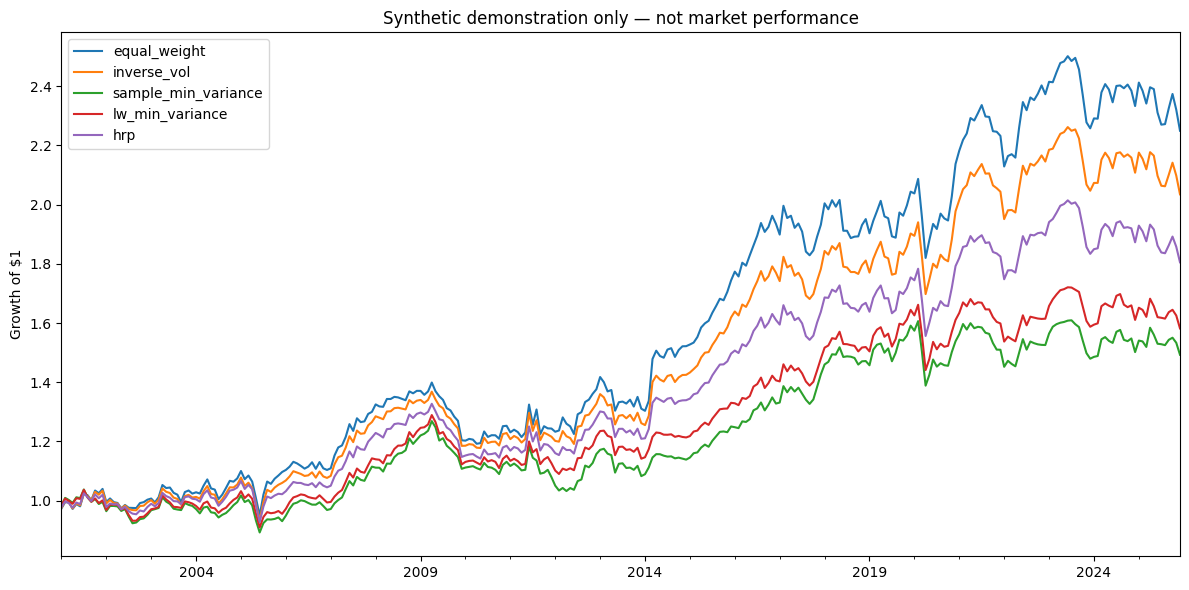

In [4]:
(1 + strategy_returns).cumprod().plot(figsize=(12, 6), title='Synthetic demonstration only — not market performance')
plt.ylabel('Growth of $1'); plt.tight_layout()

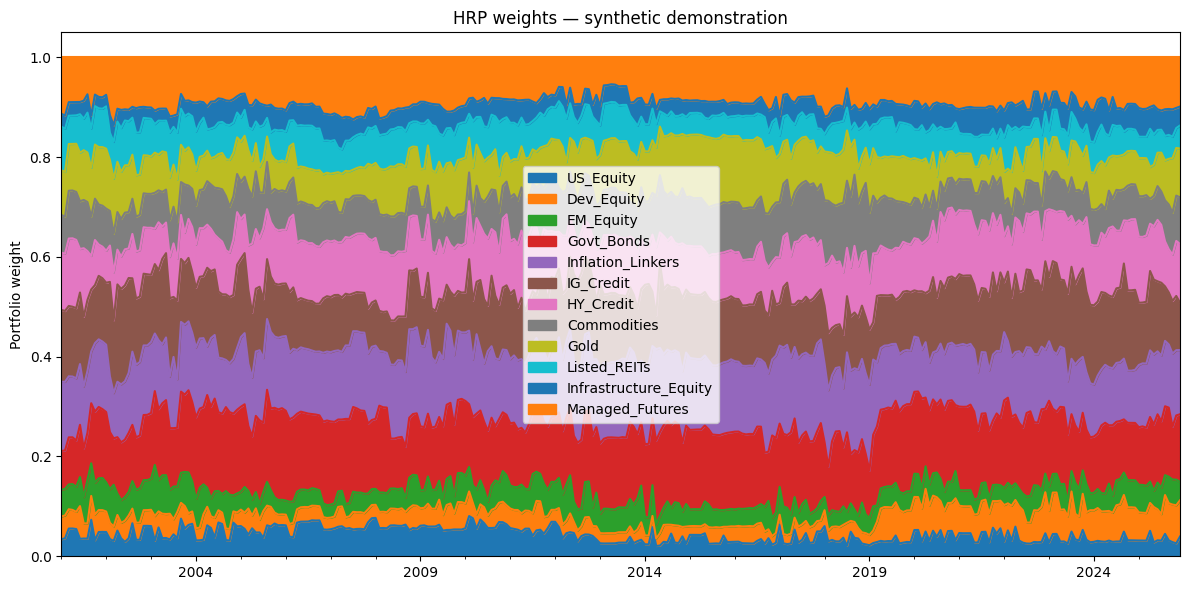

In [5]:
weights['hrp'].plot.area(figsize=(12, 6), title='HRP weights — synthetic demonstration')
plt.ylabel('Portfolio weight'); plt.tight_layout()

## 4. Research interpretation checklist
- Did shrinkage improve realized risk or just change the weight profile?
- Is HRP more stable across seeds and lookback windows?
- Do differences survive higher costs and correlation/volatility shocks?
- What is the distribution of results across seeds, rather than the best seed?
- Are findings robust to removing individual assets and changing the universe?

**No conclusion is drawn from this single synthetic run.** The next step is a pre-registered Monte Carlo grid with known covariance matrices, followed by a separate real-data study with point-in-time total-return indices.